# Chapter 5 - Development of Three Base Models

This notebook trains three classifiers on the frozen feature set selected in Chapter 4, scores them once on the validation split, and saves the probabilities that Chapter 7 reuses. The test split is deliberately not opened here.

## 5.1 Experimental setup and evaluation protocol

In [1]:
# ---------------------------------------------------------------------------
# 0. Setup: imports, portable paths, fixed seed
# ---------------------------------------------------------------------------
from pathlib import Path
import json
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, average_precision_score, f1_score,
                             precision_score, recall_score, roc_auc_score)
from xgboost import XGBClassifier

# Paths are relative to this notebook (bank/notebook/), so nothing is machine-specific.
DATA_DIR = Path("..") / "data_processed"
FIG_DIR = Path("..") / "outputs" / "chapter_05"
MODEL_DIR = DATA_DIR / "model_results"
PRED_DIR = DATA_DIR / "predictions"
for folder in (FIG_DIR, MODEL_DIR, PRED_DIR):
    folder.mkdir(parents=True, exist_ok=True)

TARGET = "default.payment.next.month"
ID_COL = "ID"
SEED = 42

spec = json.loads((DATA_DIR / "preprocessing_spec.json").read_text(encoding="utf-8"))
SELECTED = spec["selected_set"]
FEATURES = spec["feature_sets"][SELECTED]

np.random.seed(SEED)
pd.set_option("display.width", 130)
print(f"Selected feature set : {SELECTED}")
print(f"Features             : {len(FEATURES)}")

Selected feature set : A
Features             : 23


In [2]:
# 1. Load the frozen splits. The test file is deliberately not read in this chapter.
train = pd.read_csv(DATA_DIR / "train.csv")
val = pd.read_csv(DATA_DIR / "val.csv")

print(f"Train rows      : {len(train):,}")
print(f"Validation rows : {len(val):,}")
print(f"Train default % : {train[TARGET].mean() * 100:.2f}")
print(f"Validation default % : {val[TARGET].mean() * 100:.2f}")
print(f"Model columns   : {len(FEATURES)}")

Train rows      : 20,975
Validation rows : 4,495
Train default % : 22.13
Validation default % : 22.11
Model columns   : 23


In [3]:
# 2. One evaluation function, so all three models are scored identically.
#    AUC is the primary criterion; the remaining columns describe the 0.5 threshold.
def evaluate(name, model, frame):
    pred = model.predict(frame[FEATURES])
    proba = model.predict_proba(frame[FEATURES])[:, 1]
    y = frame[TARGET]
    return {
        "Model": name,
        "Accuracy": accuracy_score(y, pred),
        "Precision": precision_score(y, pred),
        "Recall": recall_score(y, pred),
        "F1": f1_score(y, pred),
        "AUC": roc_auc_score(y, proba),
        "PR-AUC": average_precision_score(y, proba),
    }

## 5.2 Model A: logistic regression

In [4]:
# 3. Model A: logistic regression with balanced class weights.
t0 = time.perf_counter()
model_a = LogisticRegression(
    C=1.0, solver="lbfgs", class_weight="balanced",
    max_iter=1000, random_state=SEED,
)
model_a.fit(train[FEATURES], train[TARGET])
time_a = time.perf_counter() - t0

metrics_a = evaluate("A  Logistic regression", model_a, val)
metrics_a["Fit time (s)"] = time_a
proba_a = model_a.predict_proba(val[FEATURES])[:, 1]
print(f"Fitted in {time_a:.2f} s")
print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in metrics_a.items()})

Fitted in 0.06 s


{'Model': 'A  Logistic regression', 'Accuracy': 0.7301, 'Precision': 0.4243, 'Recall': 0.6177, 'F1': 0.5031, 'AUC': 0.7444, 'PR-AUC': 0.4933, 'Fit time (s)': 0.0569}


## 5.3 Model B: random forest

In [5]:
# 4. Model B: random forest with balanced subsample weights.
t0 = time.perf_counter()
model_b = RandomForestClassifier(
    n_estimators=500, max_features="sqrt", min_samples_leaf=1,
    class_weight="balanced_subsample", n_jobs=-1, random_state=SEED,
)
model_b.fit(train[FEATURES], train[TARGET])
time_b = time.perf_counter() - t0

metrics_b = evaluate("B  Random forest", model_b, val)
metrics_b["Fit time (s)"] = time_b
proba_b = model_b.predict_proba(val[FEATURES])[:, 1]
print(f"Fitted in {time_b:.2f} s")
print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in metrics_b.items()})

Fitted in 2.48 s
{'Model': 'B  Random forest', 'Accuracy': 0.8142, 'Precision': 0.6556, 'Recall': 0.337, 'F1': 0.4452, 'AUC': 0.7598, 'PR-AUC': 0.5275, 'Fit time (s)': 2.4777}


## 5.4 Model C: gradient boosting

In [6]:
# 5. Model C: gradient boosting with a positive-class weight.
pos_weight = float((train[TARGET] == 0).sum() / (train[TARGET] == 1).sum())
t0 = time.perf_counter()
model_c = XGBClassifier(
    n_estimators=400, learning_rate=0.05, max_depth=4,
    subsample=0.8, colsample_bytree=0.8, scale_pos_weight=pos_weight,
    tree_method="hist", eval_metric="auc", n_jobs=-1, random_state=SEED,
)
model_c.fit(train[FEATURES], train[TARGET])
time_c = time.perf_counter() - t0

metrics_c = evaluate("C  Gradient boosting", model_c, val)
metrics_c["Fit time (s)"] = time_c
proba_c = model_c.predict_proba(val[FEATURES])[:, 1]
print(f"scale_pos_weight = {pos_weight:.2f}")
print(f"Fitted in {time_c:.2f} s")
print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in metrics_c.items()})

scale_pos_weight = 3.52
Fitted in 0.53 s
{'Model': 'C  Gradient boosting', 'Accuracy': 0.7562, 'Precision': 0.4622, 'Recall': 0.6268, 'F1': 0.532, 'AUC': 0.7757, 'PR-AUC': 0.5518, 'Fit time (s)': 0.5343}


## 5.5 Initial model comparison

In [7]:
# 6. Results table, ordered by the primary criterion.
results = pd.DataFrame([metrics_a, metrics_b, metrics_c])
results = results.sort_values("AUC", ascending=False).reset_index(drop=True)
columns = ["Model", "Accuracy", "Precision", "Recall", "F1", "AUC", "PR-AUC"]
results[columns].round({"Accuracy": 4, "Precision": 4, "Recall": 4, "F1": 4,
                        "AUC": 4, "PR-AUC": 4})

,Model,Accuracy,Precision,Recall,F1,AUC,PR-AUC
0,C Gradient boosting,0.7562,0.4622,0.6268,0.5320,0.7757,0.5518
1,B Random forest,0.8142,0.6556,0.3370,0.4452,0.7598,0.5275
2,A Logistic regression,0.7301,0.4243,0.6177,0.5031,0.7444,0.4933


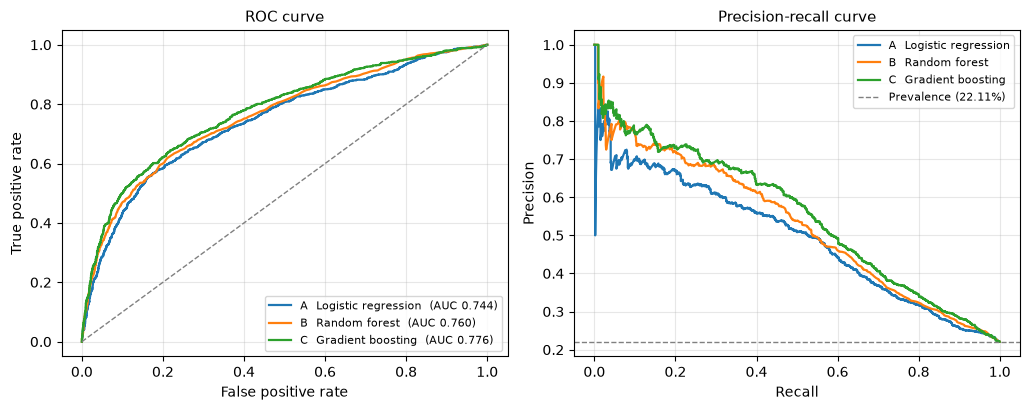

In [8]:
# 7. ROC and precision-recall curves on the validation set.
from sklearn.metrics import precision_recall_curve, roc_curve

fig, axes = plt.subplots(1, 2, figsize=(10.4, 4.2))
prevalence = val[TARGET].mean()
curves = (("A  Logistic regression", proba_a),
          ("B  Random forest", proba_b),
          ("C  Gradient boosting", proba_c))

for label, proba in curves:
    fpr, tpr, _ = roc_curve(val[TARGET], proba)
    precision, recall, _ = precision_recall_curve(val[TARGET], proba)
    auc = roc_auc_score(val[TARGET], proba)
    axes[0].plot(fpr, tpr, linewidth=1.6, label=f"{label}  (AUC {auc:.3f})")
    axes[1].plot(recall, precision, linewidth=1.6, label=label)

axes[0].plot([0, 1], [0, 1], linestyle="--", color="grey", linewidth=1)
axes[0].set_xlabel("False positive rate")
axes[0].set_ylabel("True positive rate")
axes[0].set_title("ROC curve", fontsize=11)
axes[0].legend(fontsize=8, loc="lower right")

axes[1].axhline(prevalence, linestyle="--", color="grey", linewidth=1,
                label=f"Prevalence ({prevalence:.2%})")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-recall curve", fontsize=11)
axes[1].legend(fontsize=8, loc="upper right")

for ax in axes:
    ax.grid(alpha=0.3)

fig.tight_layout()
fig.savefig(FIG_DIR / "fig_5_6_roc_pr.png")
plt.show()

In [9]:
# 8. Persist the validation probabilities and the metric table.
predictions = pd.DataFrame({
    ID_COL: val[ID_COL],
    TARGET: val[TARGET],
    "p_A": proba_a,
    "p_B": proba_b,
    "p_C": proba_c,
})
predictions.to_csv(PRED_DIR / "base_models_val.csv", index=False)

table = results.round({"Accuracy": 4, "Precision": 4, "Recall": 4, "F1": 4,
                       "AUC": 4, "PR-AUC": 4, "Fit time (s)": 2})
table.to_csv(MODEL_DIR / "base_models_val.csv", index=False)

print("Saved:")
print(f"  {PRED_DIR / 'base_models_val.csv'}")
print(f"  {MODEL_DIR / 'base_models_val.csv'}")
print(f"  {FIG_DIR / 'fig_5_6_roc_pr.png'}")

Saved:
  ..\data_processed\predictions\base_models_val.csv
  ..\data_processed\model_results\base_models_val.csv
  ..\outputs\chapter_05\fig_5_6_roc_pr.png
